# 02 · Baseline: a propensity ("likely visitor") model

**What a typical marketing team would do:** train a model that predicts *who will visit*, then email the customers with the highest predicted probability.

**Why this can be the wrong question:** a high probability of visiting does not mean the email *causes* the visit. Many of these customers would visit anyway ("sure things"). This notebook builds that baseline and checks, **using the training data only**, whether high-propensity customers are also the ones the email moves.

Everything here uses cross-validated (out-of-fold) predictions on the training set. The test set stays untouched until notebook 04.

In [1]:
# Make `src` importable from the notebooks folder (works on Windows and macOS)
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src.config import *
FIG_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_json(obj, name):
    (RESULTS_DIR / name).write_text(json.dumps(obj, indent=2, default=float))

In [ ]:
import joblib
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src.preprocessing import make_split, fit_transform_features
from src.models import PropensityModel, base_classifier
from src.evaluation import uplift_by_decile

train, validation, test = make_split()

X_tr, X_val, X_te, pre = fit_transform_features(
    train, validation, test
)

print("Training:", X_tr.shape)
print("Validation:", X_val.shape)
print("Testing:", X_te.shape)
print("Features:", list(X_tr.columns))

Training: (38400, 11)
Validation: (12800, 11)
Testing: (12800, 11)
Features: ['zip_code_Rural', 'zip_code_Surburban', 'zip_code_Urban', 'channel_Multichannel', 'channel_Phone', 'channel_Web', 'recency', 'history', 'mens', 'womens', 'newbie']


## 1. Fit the propensity model
Target: `visit`. Features: the same 7 customer features the uplift models will use (one-hot encoded zip code and channel). The arm is **not** a feature: the model only describes the customer.

Hyper-parameters are chosen by 3-fold cross-validation on the training set (log-loss). The tuned model is then fitted on the full training set and saved.

In [3]:
prop = PropensityModel().fit(X_tr, train["visit"])
print("Best parameters:", prop.params_)
joblib.dump({"model": prop, "preprocessor": pre}, MODELS_DIR / "propensity.joblib")

Best parameters: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}


['C:\\Users\\User\\Desktop\\ai-marketing-uplift-optimization-v2\\ai-marketing-uplift-optimization\\models\\propensity.joblib']

## 2. Out-of-fold predictions on the training set
Each training customer is scored by a model that did not see them (5 folds). This gives an honest view of the model without using the test set.

In [4]:
oof = cross_val_predict(base_classifier(**prop.params_), X_tr, train["visit"],
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
auc = roc_auc_score(train["visit"], oof)
print(f"Out-of-fold ROC AUC for predicting visit: {auc:.3f}")

Out-of-fold ROC AUC for predicting visit: 0.621


## 3. Does high propensity mean high uplift?
We cut the training customers into 10 equal groups (deciles) by predicted visit probability, decile 1 = most likely to visit. Inside each decile we compare emailed vs not-emailed customers. Because emails were random, that difference estimates the email's effect **for that decile**.

* `rate_control` = how often they visit **without** an email (if high: "sure things").
* `uplift` = extra visits caused by the email, with a 95% CI.

In [5]:
dec = {}
for arm in (1, 2):
    m = train["arm"].isin([0, arm]).to_numpy()
    dec[arm] = uplift_by_decile(train["visit"].to_numpy()[m], (train["arm"].to_numpy()[m] == arm).astype(int), oof[m])
    print(ARMS[arm]); display(dec[arm])

Mens E-Mail


,decile,n_treated,n_control,rate_treated,rate_control,uplift,ci_lo,ci_hi
0,1,1320,1237,0.3083,0.1989,0.1095,0.0761,0.1429
1,2,1293,1264,0.2351,0.1614,0.0737,0.0430,0.1045
2,3,1300,1257,0.2238,0.1360,0.0878,0.0583,0.1174
3,4,1254,1302,0.2049,0.1091,0.0959,0.0678,0.1239
4,5,1297,1260,0.1742,0.1079,0.0663,0.0395,0.0932
5,6,1261,1296,0.1634,0.1088,0.0546,0.0280,0.0811
6,7,1250,1306,0.1616,0.0850,0.0766,0.0512,0.1020
7,8,1251,1306,0.1447,0.0773,0.0673,0.0431,0.0916
8,9,1254,1303,0.1220,0.0606,0.0614,0.0391,0.0837
9,10,1304,1252,0.0836,0.0208,0.0628,0.0458,0.0798


Womens E-Mail


,decile,n_treated,n_control,rate_treated,rate_control,uplift,ci_lo,ci_hi
0,1,1296,1266,0.2554,0.1998,0.0556,0.0232,0.0880
1,2,1316,1246,0.2006,0.1589,0.0417,0.0120,0.0714
2,3,1296,1265,0.1775,0.1352,0.0423,0.0142,0.0704
3,4,1286,1276,0.1641,0.1105,0.0536,0.0270,0.0801
4,5,1268,1293,0.1680,0.1067,0.0613,0.0347,0.0878
5,6,1265,1297,0.1344,0.1087,0.0257,0.0004,0.0510
6,7,1319,1243,0.1213,0.0861,0.0352,0.0117,0.0588
7,8,1257,1304,0.1265,0.0759,0.0506,0.0272,0.0739
8,9,1247,1315,0.1002,0.0616,0.0386,0.0175,0.0598
9,10,1283,1278,0.0624,0.0219,0.0404,0.0250,0.0559


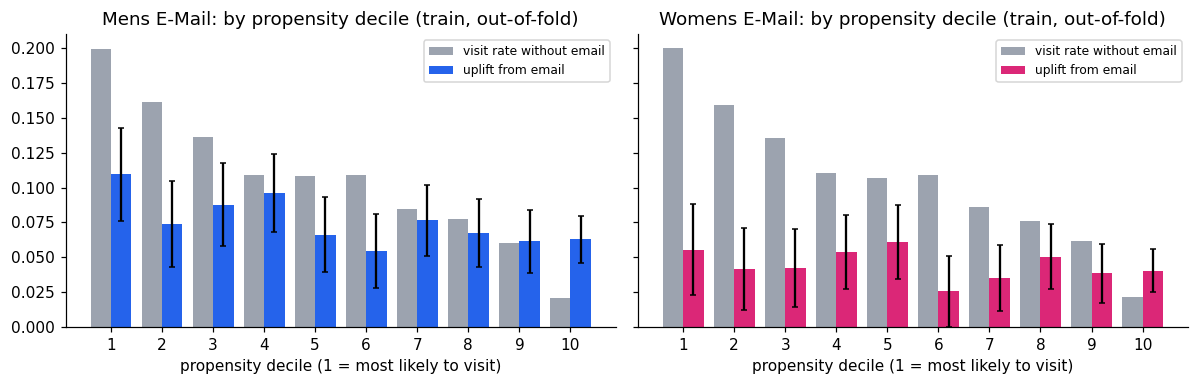

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, arm, col in zip(axes, (1, 2), ("#2563EB", "#DB2777")):
    d = dec[arm]
    ax.bar(d.decile - 0.2, d.rate_control, width=0.4, color="#9CA3AF", label="visit rate without email")
    ax.bar(d.decile + 0.2, d.uplift, width=0.4, color=col, label="uplift from email",
           yerr=[d.uplift - d.ci_lo, d.ci_hi - d.uplift], capsize=2)
    ax.set_title(f"{ARMS[arm]}: by propensity decile (train, out-of-fold)"); ax.set_xlabel("propensity decile (1 = most likely to visit)")
    ax.set_xticks(range(1, 11)); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_propensity_deciles.png", bbox_inches="tight"); plt.show()

In [7]:
top = {arm: dec[arm].iloc[:2] for arm in (1, 2)}
summary = {"oof_auc": auc, "best_params": prop.params_,
           "deciles": {ARM_SHORT[a]: dec[a].to_dict("records") for a in (1, 2)},
           "corr_propensity_vs_control_rate": {ARM_SHORT[a]: float(np.corrcoef(dec[a].decile, dec[a].rate_control)[0, 1]) for a in (1, 2)},
           "corr_propensity_vs_uplift": {ARM_SHORT[a]: float(np.corrcoef(dec[a].decile, dec[a].uplift)[0, 1]) for a in (1, 2)}}
save_json(summary, "02_propensity.json")
print(json.dumps({k: v for k, v in summary.items() if k.startswith("corr")}, indent=1))

{
 "corr_propensity_vs_control_rate": {
  "mens": -0.9661136617956795,
  "womens": -0.9655851883841444
 },
 "corr_propensity_vs_uplift": {
  "mens": -0.7217836679365943,
  "womens": -0.3551363001558448
 }
}


## What we found
* The propensity model predicts visits moderately well (out-of-fold ROC AUC **0.62**).
* It mainly ranks customers by how likely they are to visit **anyway**: in the men's-email analysis, the visit rate *without* an email falls from **19.4%** in the top decile to **2.8%** in the bottom decile.
* The email's effect is only mildly related to propensity: men's email uplift is **+9.9 points** in the top decile vs **+6.2** in the bottom, with heavily overlapping CIs; women's email **+5.5** vs **+3.3**.
* So among emailed visitors in the top men's-email decile, about two thirds (19.4 of 29.3 points) would have visited anyway: these are the **sure things** a propensity model loves.
* Honest note: propensity is *not useless* here, because uplift is slightly higher at the top. Whether uplift models beat it is tested on the held-out set in notebook 04.